# Projecting FHIR data in SQL

InterSystems FHIR servers have the ability to project data stored in the FHIR Server into SQL tables. This is particularly powerful for looking at data at the population level, rather than querying individual patients or resources. 

The primary method for doing using this is through the FHIR Server Management Portal, accessible at [http://localhost:52773/csp/fhir-management/index.html](http://localhost:52773/csp/fhir-management/index.html). It is also possible to do this in an automated fashion using Python code via an experimental library available from [github](https://github.com/isc-ging/iris-fhirsql). 

Note, all links used here will assume the FHIR Server is setup using the docker template in this repo, for other setups, you may need to change the server (IP address/web address), web port and credentials. 

## Using the FHIR SQL Builder

The FHIR SQL projection is defined in 3 steps (with two hidden extra steps). You need to define: 
- The **Repository** being used (this is not automatically discovered)
- The **Credentials** being used
- An **Analysis** — this is a set (possibly a subset) of data in your FHIR Repository. By creating an analysis from a subset of data, you can create your specification and workflow before performing the same projections on all of the data in the FHIR Server.
- A **Transform Specification** — the choice of data to be included in SQL tables
- A **Projection** — The combination of an analysis, a transform specification, with a given SQL package.

These will be shown in sequence below.

 ### FHIR SQL Admin 

From the FHIR Management Portal, select the FHIR-SQL icon to expand the options, then select the settings icon, you should see the following page:

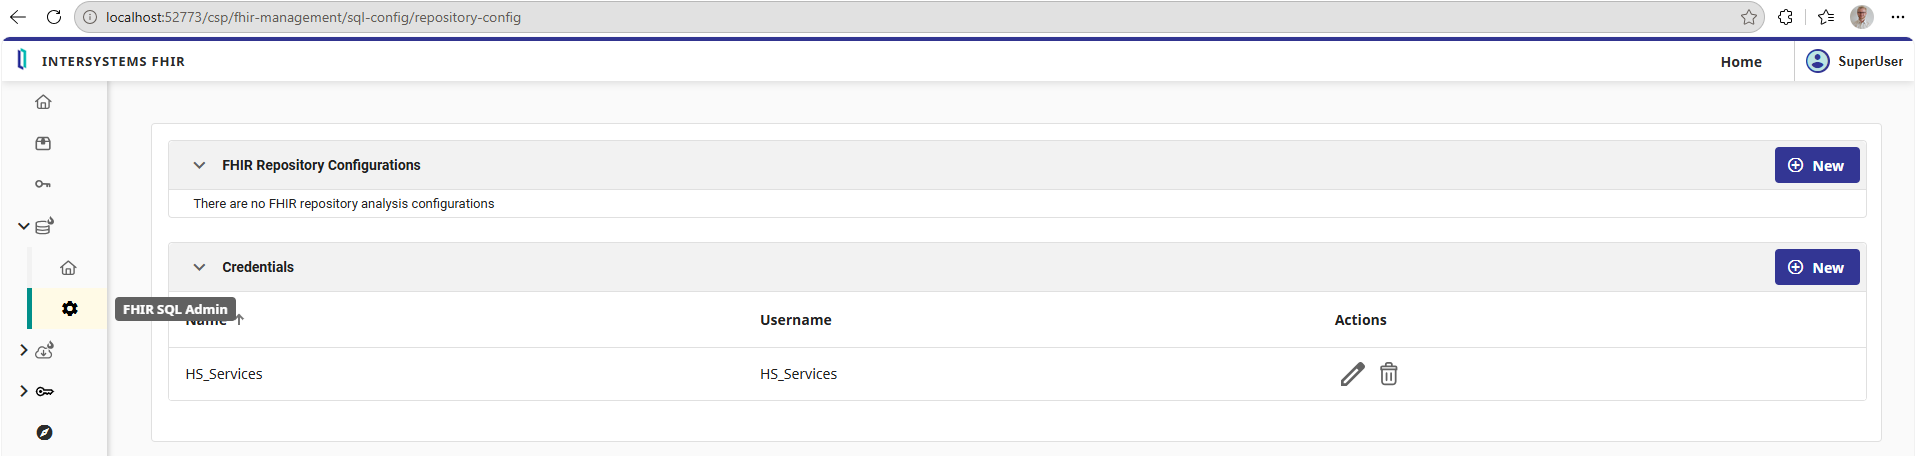

#### Define Credentials

Click the `+ New` button besides the *Credentials* block. You'll see a wizard pop up. Here, you just need to fill out the Username and Password for a valid user, you also need to give these credentials a name: 

 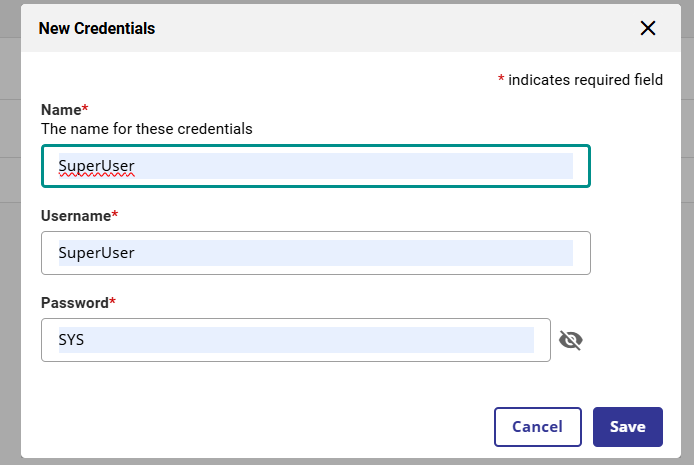


If you are *not* using a superuser with `%All` resources, the user will need the `FSB_Administrator` resource to create the FHIR Repository configuration in the next step. There are also other resources to control different access levels to this. 

#### Define Repository Configuration

Click the `+ New` button besides the *FHIR Repository Configurations* block, again a wizard will pop up. 

Fill this out with the correct values for your setup:

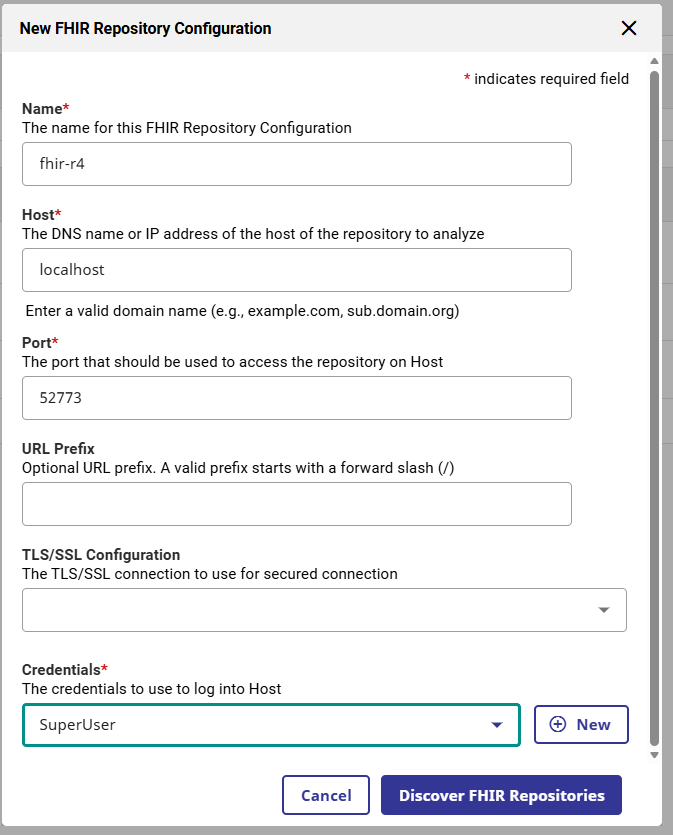

These are (if you are using the template in this repo):

- Name: *fhir-r4* (User defined label)
- Host: *localhost* (Server)
- Port: *52773* (Web port)
- URL Prefix: *leave blank*
- TLS/SSL: *leave blank*
- Credentials: *Select credentials created above from dropdown*

 After filling these out, click `Discover FHIR Repositories`. 


**Note: if you are using a container with a ports mapped to a different port (e.g. "32783:52773" in docker-compose.yaml), it is the internal web port, 52773 needed here.**

After pressing `Discover FHIR Repositories`, scroll down to see the FHIR Repository endpoints discovered: 

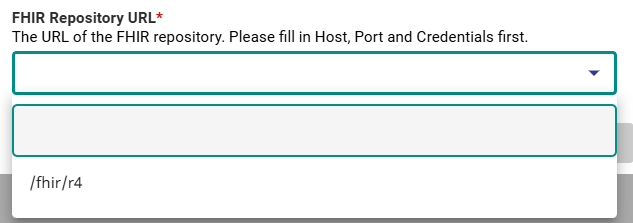

Select `/fhir/r4` and click `Save`. 



#### FHIR SQL Projections

From the left-hand menu, select the Home icon under the FHIR-SQL dropdown, or go to http://localhost:52773/csp/fhir-management/sql-projections/home. 

#### Define Analysis 

Click `+ New` next to the *Analyses* block and fill in the wizard. 

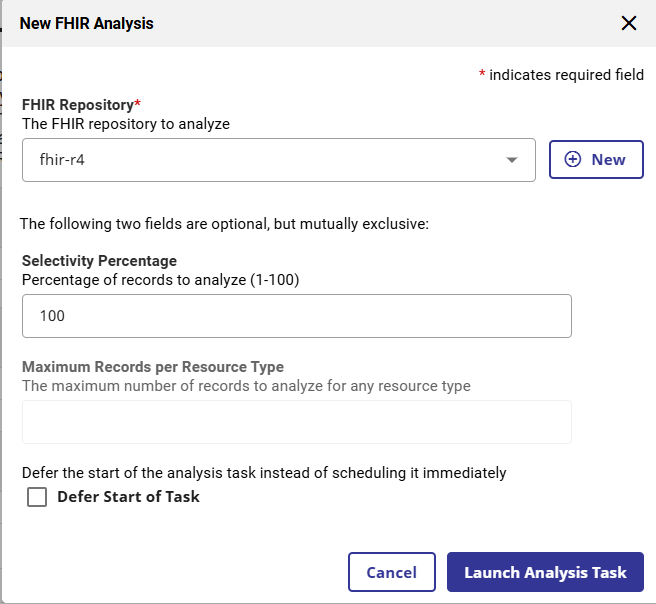

Select the name of the repository configuration you just created, *fhir-r4* and give *100* for selectivity percentage. For full-size FHIR servers, you probably want to use a subset of data when defining the transformation and trying the projection, however as this is a small scale server you can use the full dataset. 

Select `Launch Analysis Task`, this will run the analysis. The time taken for this depends on the number of resources in the dataset. You will see the analysis, along with a status and a `Percent Complete` added to the block. 

You will need to wait for this to complete before continuing.

#### Define Transformation Specifications 

This is the step where you choose the data you want to use. Click `+ New` to launch this. 

In the Wizard, give your specification a unique name (ideally something relevant to the data) and choose the complete analysis from the step above. You can also give a description of the transform. 

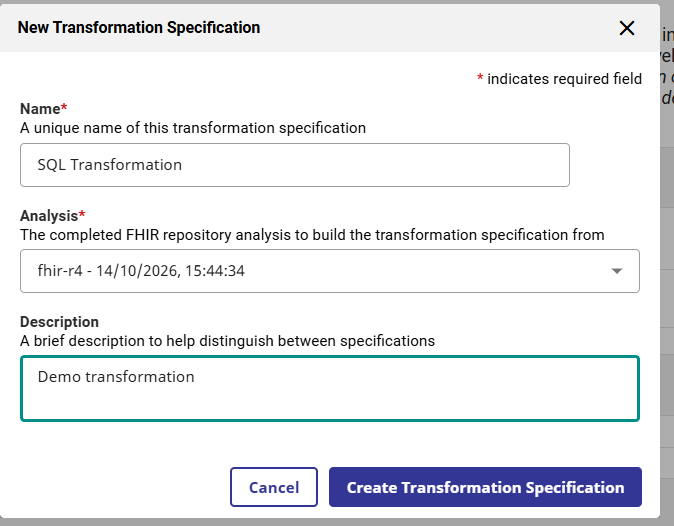

Click `Create Transform Spec` to enter the specification builder.

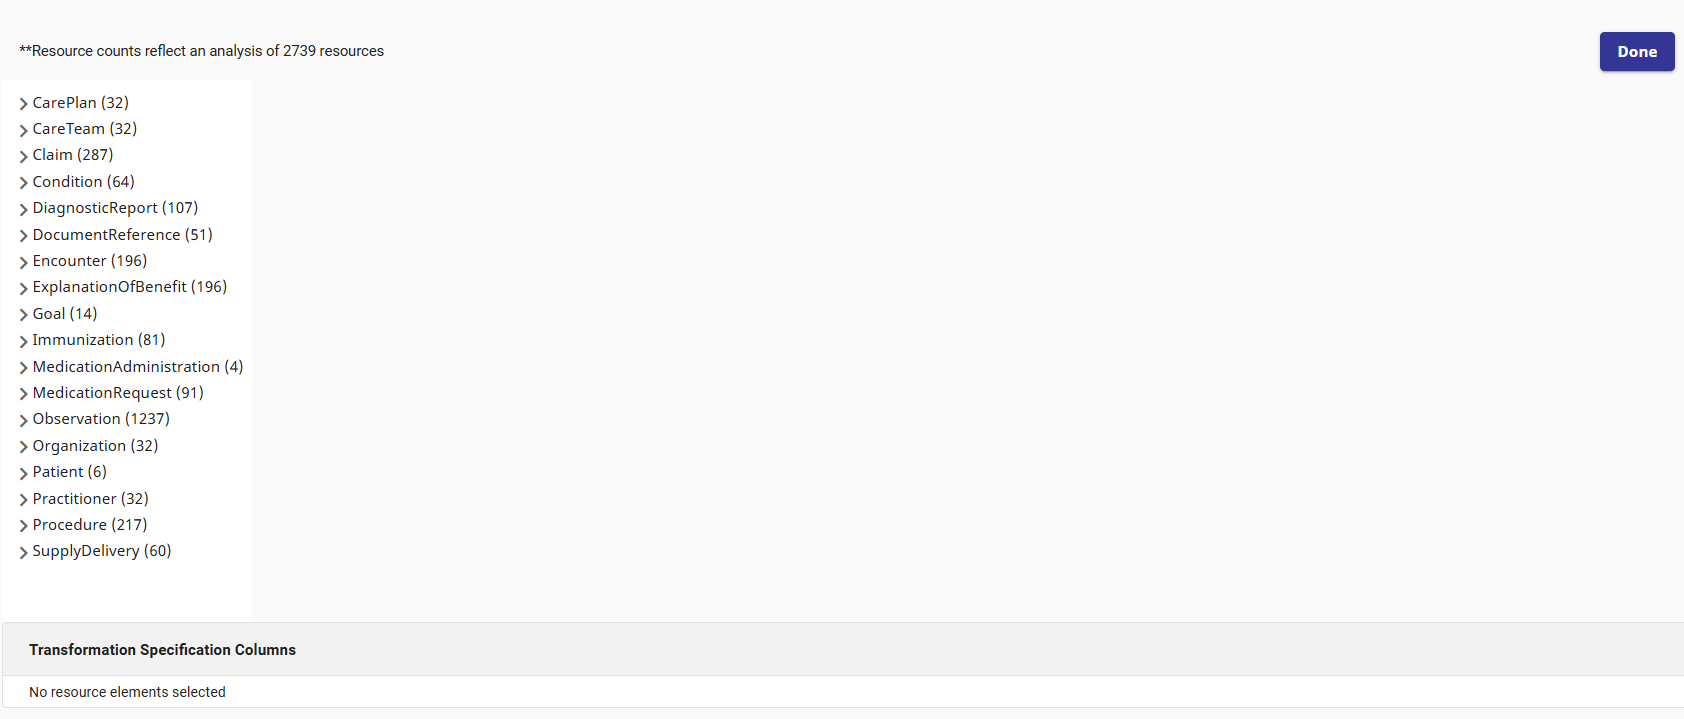


The left-hand panel has a list of resources which can be expanded. 

Select `Patient` to look inside the Patient Resource, then Select `name`, then tick the checkbox for `family` and `given`. You can rename these values using the box after *as*, rename them *Surname* and *FirstName* respectively: 

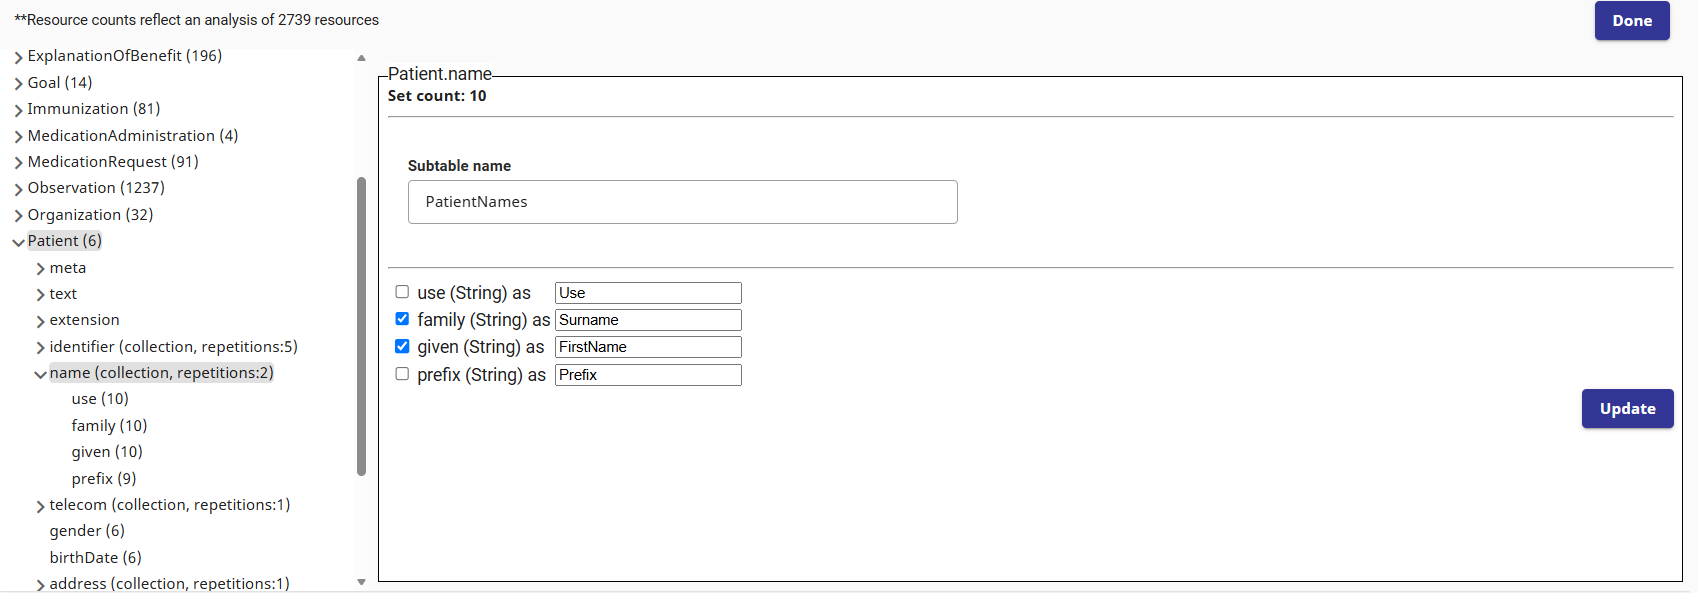

Click `Update` to add these to the Specification. These will become columns in SQL tables

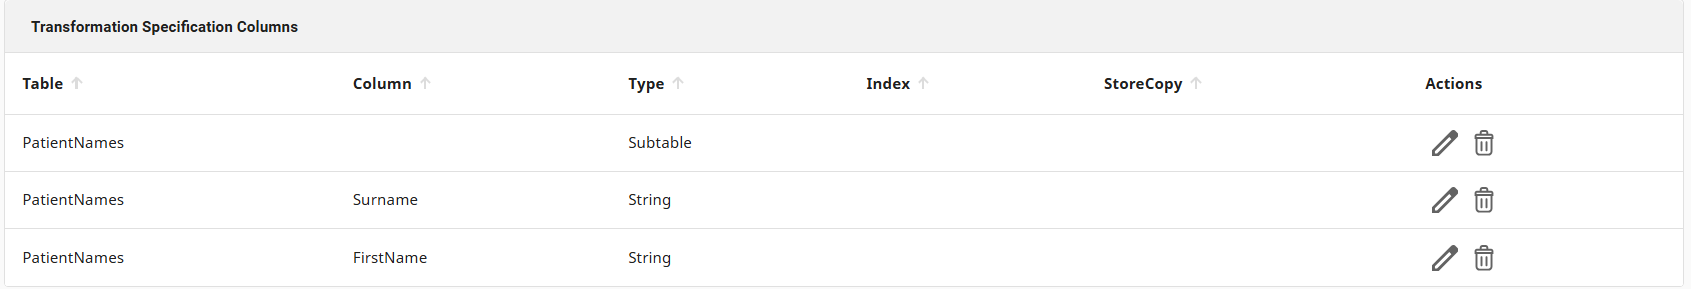


Imagine you are interested in the different conditions individual patients have, you can try the following:

Go to *Condition* -> *code* -> *text*. You can click `Show Histogram` to see a histogram of the values for this element. 

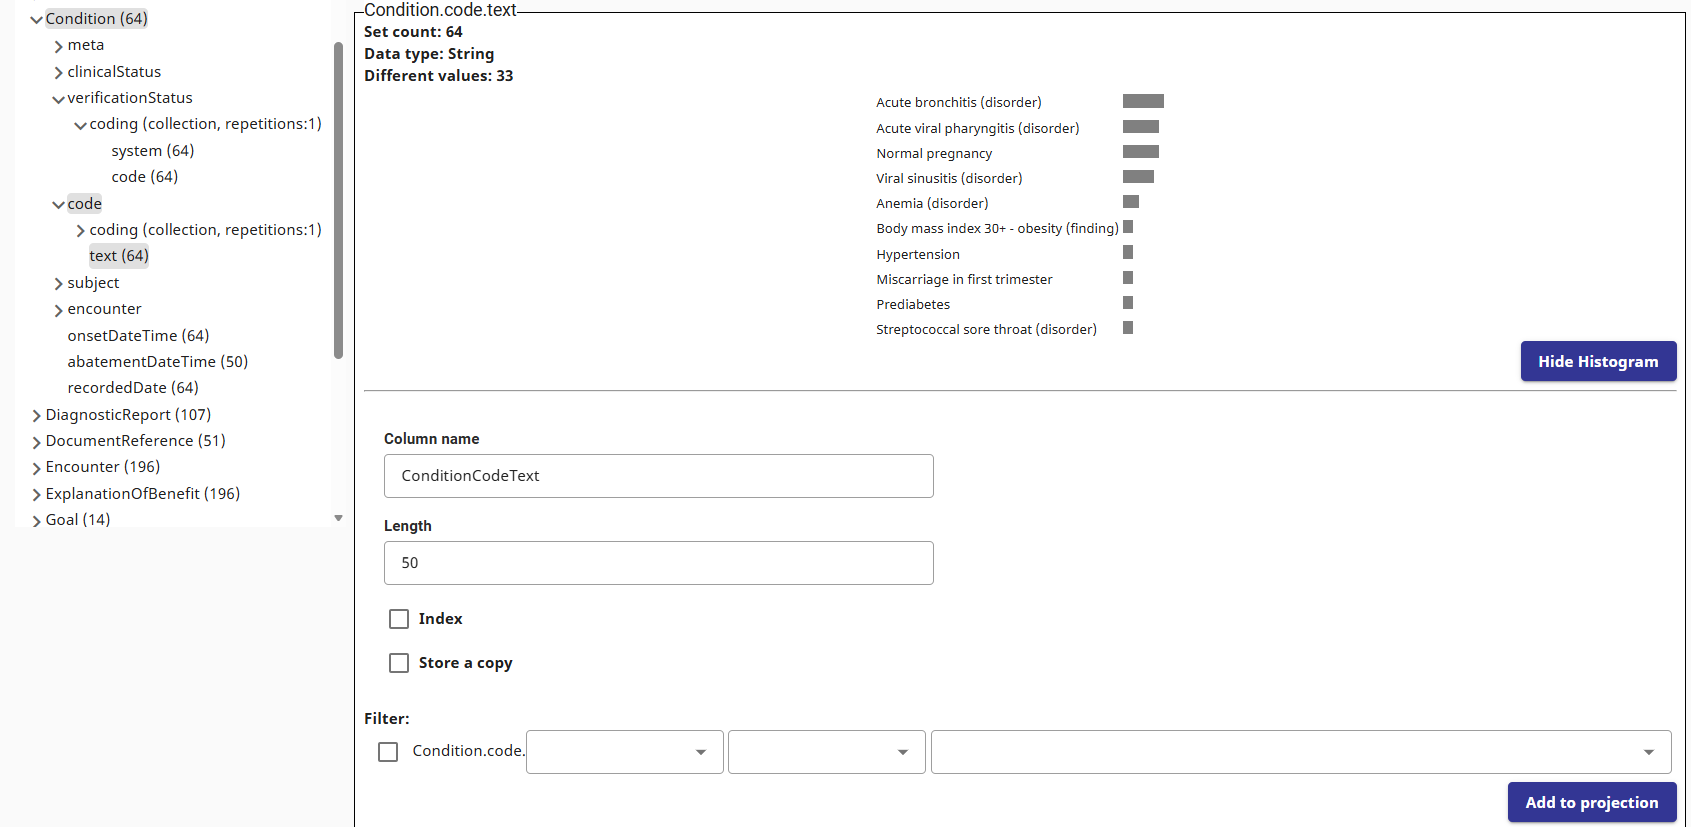

Click `Add to Projection`. 

You will also need to add the patient reference for the condition resource by selecting *Condition* -> *subject* -> *reference* and adding this to the projection. 

Once added, you can select `Done` at the top of the page. 


To summarise this specification, you are including: 
- Patient FirstName(s) and Surname
- Condition Text
- The Patient Reference for the conditions


After creating this specification, you can edit it or download it as a JSON spec so you can import it elsewhere.

#### Define Projection

Once a specification is made, it can be projected into a SQL package by selecting `+ New` next to the *Projections* block: 

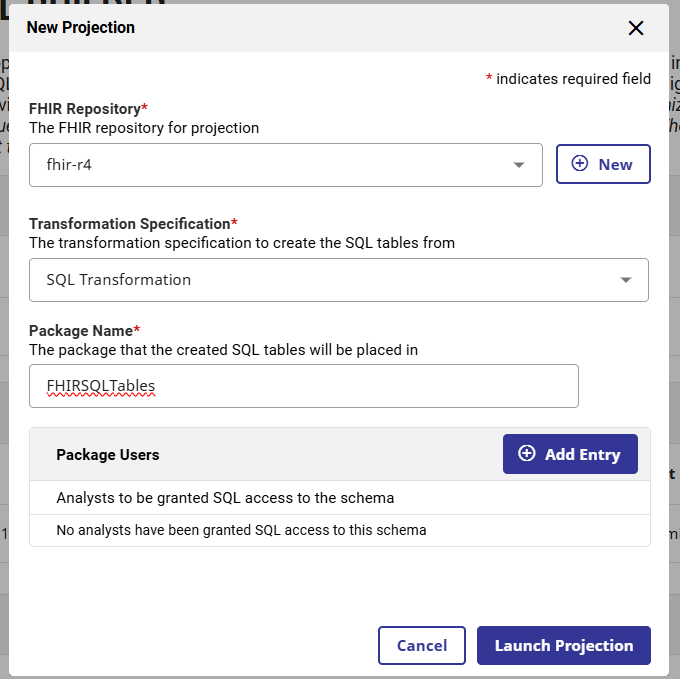

You need to give the projections a package name (this is the prefix for the SQL table names) as well as the FHIR Repository and Transformation Specification created above. You can give specific users SQL access here. Again, this is important if you are *not* using a superuser account in a demo system. 


Click `Launch Projection`. 


### Querying the tables

After the Projection is launched, you should be able to query the tables. You can do this from the [SQL Explorer](http://localhost:52773/csp/sys/exp/%25CSP.UI.Portal.SQL.Home.zen?$NAMESPACE=FHIRSERVER) in the Management Portal: 

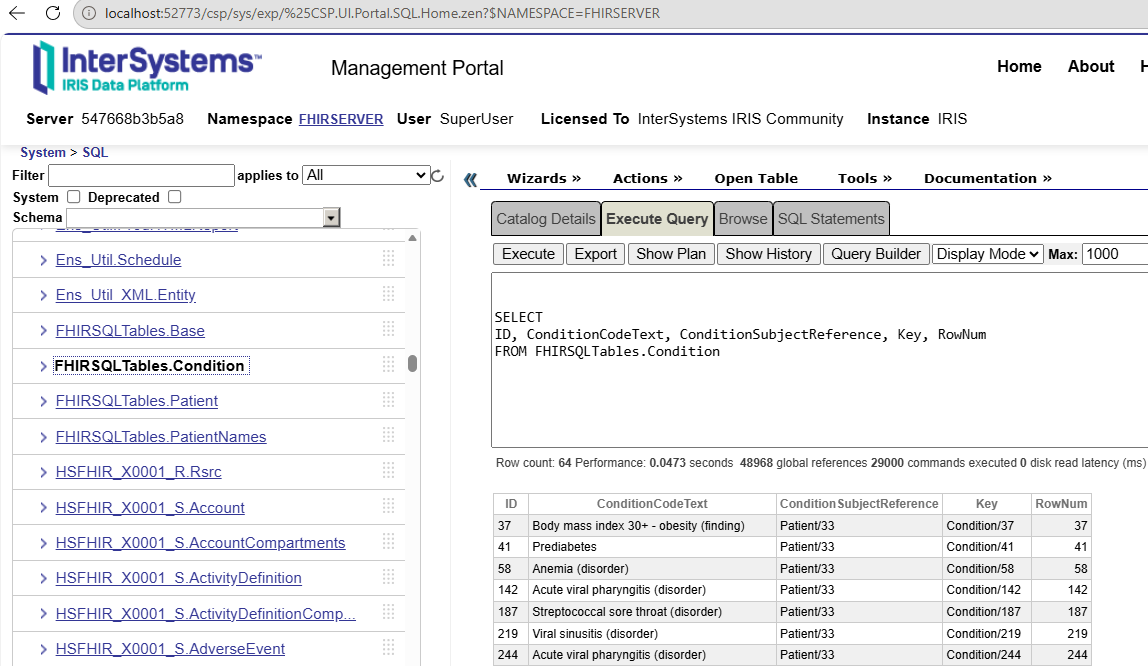

Or from Python with the following: 



In [5]:
import iris 

conn = iris.connect("localhost", 1972, "FHIRSERVER", "SuperUser", "SYS")
cursor = conn.cursor() 

cursor.execute("""SELECT 
ID, ConditionCodeText, ConditionSubjectReference, Key, RowNum
FROM FHIRSQLTables.Condition""")

results = cursor.fetchone()

print(list(results))


[37, 'Body mass index 30+ - obesity (finding)', 'Patient/33', 'Condition/37', 37]


You can also combine multiple tables using joins: 


In [8]:

cursor.execute("""SELECT c.ID, c.ConditionCodeText, pn.FirstName, pn.Surname
FROM FHIRSQLTables.Condition c
JOIN FHIRSQLTables.PatientNames pn
  ON c.ConditionSubjectReference = 'Patient/' || pn.Patient
ORDER BY c.ID, pn.PatientNamesNumber""")

results = cursor.fetchmany(5) 

for row in results: 
    print(list(row))

[37, 'Body mass index 30+ - obesity (finding)', 'Alisia5', 'Ziemann98']
[37, 'Body mass index 30+ - obesity (finding)', 'Alisia5', 'Dietrich576']
[41, 'Prediabetes', 'Alisia5', 'Ziemann98']
[41, 'Prediabetes', 'Alisia5', 'Dietrich576']
[58, 'Anemia (disorder)', 'Alisia5', 'Ziemann98']


This is a simple demo example, but projecting FHIR data as SQL tables can be powerful as a way of accessing the data for analytics in a format analysts are used to. 

## Projecting Data Programmatically 

As mentioned in the introduction, there is an experimental community project to give a programmatic wrapper around these steps available at https://github.com/isc-ging/iris-fhirsql

To install it, clone the repo: 

```sh
git clone https://github.com/isc-ging/iris-fhirsql.git
```

and run:

```sh
pip install -e ./iris-fhirsql/ 
```

You may need to restart the jupyter kernal after this. Then try the following: 

In [2]:
from iris_fhirsql import FHIRSQLClient

client = FHIRSQLClient(
    hostname="localhost",
    port=52773,
    username="SuperUser",
    password="SYS"
)

To use the client to perform the transformation as above, use the following: 


In [3]:
# Create credentials 
cred = client.credentials.create(
    system_name="SQLBuilderCreds",
    username="SuperUser",
    password="SYS"
)

# Create repository
repo = client.repositories.create(
    name="SQLBuilderConfig",
    host="localhost",
    fhir_url="/fhir/r4",
    credentials_name=cred.system_name
)

# Launch Analysis
analysis = client.analysis.create(
    repository_id=repo.id,
    selectivity_percentage=100  
)

# Wait for completion
while analysis.status != "completed":
    analysis = client.analysis.get(analysis.id)



To create a transformation spec, use the `TransformSpecBuilder`: 

Here we are selecting patient demographics (FirstName, LastName, gender and birthDate) from the Patient Resource.

After this, we submit a specification to the FHIR SQL Builder by using `client.transform_specs.create_from_builder()`


In [6]:
from iris_fhirsql import TransformSpecBuilder

builder = TransformSpecBuilder("Patient Demographics", analysis_id=analysis.id)
builder.add_field("Patient", "Patient.name.family", "String", name="LastName", length=50)
builder.add_field("Patient", "Patient.name.given", "String", name="FirstName", length=50)
builder.add_field("Patient", "Patient.gender", "String", name="PatientGender", length=10, index=True)
builder.add_field("Patient", "Patient.birthDate", "String", name="PatientBirthDate", length=10)

spec = client.transform_specs.create_from_builder(builder)

Then create the projection: 

In [8]:
proj = client.projections.create(repository_id=repo.id, spec_id=spec.id,
                                 package_name="patientdata")

We can now query this: 

In [13]:
import iris 

conn = iris.connect("localhost", 1972, "FHIRSERVER", "SuperUser", "SYS")
cursor = conn.cursor() 

cursor.execute("""SELECT 
ID,key, FirstName, LastName, PatientBirthDate, PatientGender, RowNum
FROM patientdata.Patient""")

results = cursor.fetchall()

for result in results: 
    print(list(result))


[16, 'Patient/16', 'Aurora248', 'Hoeger474', '2023-05-30', 'female', 16]
[33, 'Patient/33', 'Alisia5', 'Ziemann98', '1956-03-15', 'female', 33]
[736, 'Patient/736', 'Lakita48', 'Jacobson885', '1980-06-16', 'female', 736]
[1350, 'Patient/1350', 'Miquel905', 'Wolff180', '1971-10-04', 'male', 1350]
[1805, 'Patient/1805', 'Sherry479', 'Spinka232', '1983-09-17', 'female', 1805]
[2329, 'Patient/2329', 'Tish', 'Lemke', '1978-06-25', 'female', 2329]
